Good start! Some comments for improvement:

    The dataset needs to be explained in the beginning of the EDA.
    Dropping duration makes sense, but should be explained
    The metrics for training should also be printed, to discuss overfitting etc.
    In this assignment when tuning; you should test each value for each hyper parameter multiple times (3-5) instead of using random state, and then take the average. This would make your results less likely to be random.
    I could not see any discussion regarding why your choice of main metric is f1.
    Since you are tuning based on f1, it would make sense to test a higher value for max depth since your results show the f1-score increasing when max depth is increased.
    Similarly for min samples split; since 20 gave the best f1-score, you should test a few more values around this number. Nice plot after tuning this! This shows what parameter value you should test more values close to:)
    Similarly for var smoothing
    The results should be discussed more in relation to the domain of the dataset

Except for my comments you did a solid job! Good structure, content and well commented. 

these comments from the previous, now the assignment:

an exploratory data analysis
data processing with multiple alternatives
automated hyperparameter tuning (ideally also of processing parameters/choices)

    You should tune at least three model parameters where possible. Groups of one can aim for at least two. Groups of three should aim for at least four.

evaluation using accuracy, precision, recall, and the f-measure
evaluation using confusion matrices and suitable plots 

The submission should be one or more Jupyter notebooks compressed into either a zip or tar.gz. You should take care to make the presentation well structured easy to read. Use markdown to document all relevant outputs.


In [25]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sb 
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import TargetEncoder, StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [26]:
dataset = pd.read_csv('../data/online_shoppers_intention.csv')
dataset.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


# DATA EXPLANATION:

Administration, Administrative_Duration, Informational, Informational_Duration, ProductRelated and Product Related_Duration. Each one represents the number of  different types of pages visited in a sesion and the total time of that session.

BounceRates, ExitRates and PageValues represents the metrics given in Google Analytics. Being BounceRates the percentage of people than enters and "bounce" back withouth doing another action, ExitRates is the calculations of all the pageviews of the page, and then the percent of those who were in the last session  and the PageValue is the average value that a page has to have for a visitor to visit it and then complete an e-commerce transaction.

SpecialDay feature shows if a page is visited in a holiday or a marked day such as Mother's Day, Valentine's day.

The next features are more easy to understand: Month, OperatingSystems, Browser, Region, TrafficTYpe, VisitorType, Weekend and Revenue. Some of these columns are anonymous so we cant really tell for example which OS is forn each number, or which region is which number, but that won't be a problem for the study of this dataset, we will only get a foggy output of some features.

This dataset consists of 12330 sessions of shopping. All of the data was collected within a 1 year period to avoid atypical data, such as holidays, special campaigns, etc.



# EDA:





In [27]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

We don't have any null Values which is going to enrich our study and make our lifes easier because we don't have to deal with Nan Values.

In [28]:
dataset.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


array([[<Axes: title={'center': 'Administrative'}>,
        <Axes: title={'center': 'Administrative_Duration'}>,
        <Axes: title={'center': 'Informational'}>,
        <Axes: title={'center': 'Informational_Duration'}>],
       [<Axes: title={'center': 'ProductRelated'}>,
        <Axes: title={'center': 'ProductRelated_Duration'}>,
        <Axes: title={'center': 'BounceRates'}>,
        <Axes: title={'center': 'ExitRates'}>],
       [<Axes: title={'center': 'PageValues'}>,
        <Axes: title={'center': 'SpecialDay'}>,
        <Axes: title={'center': 'OperatingSystems'}>,
        <Axes: title={'center': 'Browser'}>],
       [<Axes: title={'center': 'Region'}>,
        <Axes: title={'center': 'TrafficType'}>, <Axes: >, <Axes: >]],
      dtype=object)

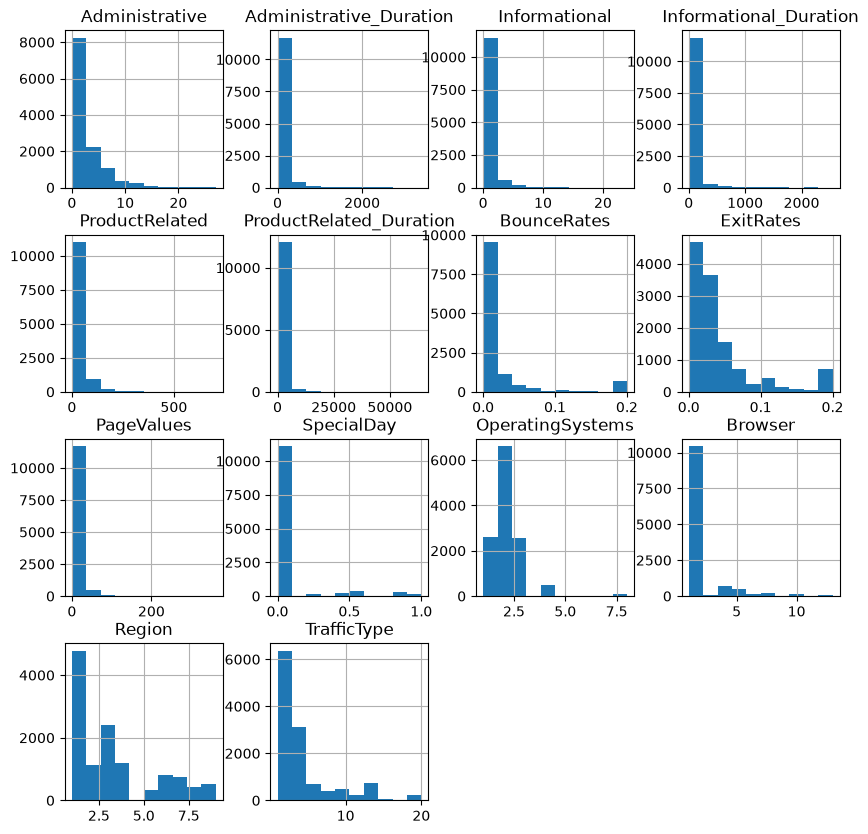

In [29]:
#We make our first EDA by using histograms


dataset.hist(figsize=(10,10))


<Axes: xlabel='VisitorType', ylabel='count'>

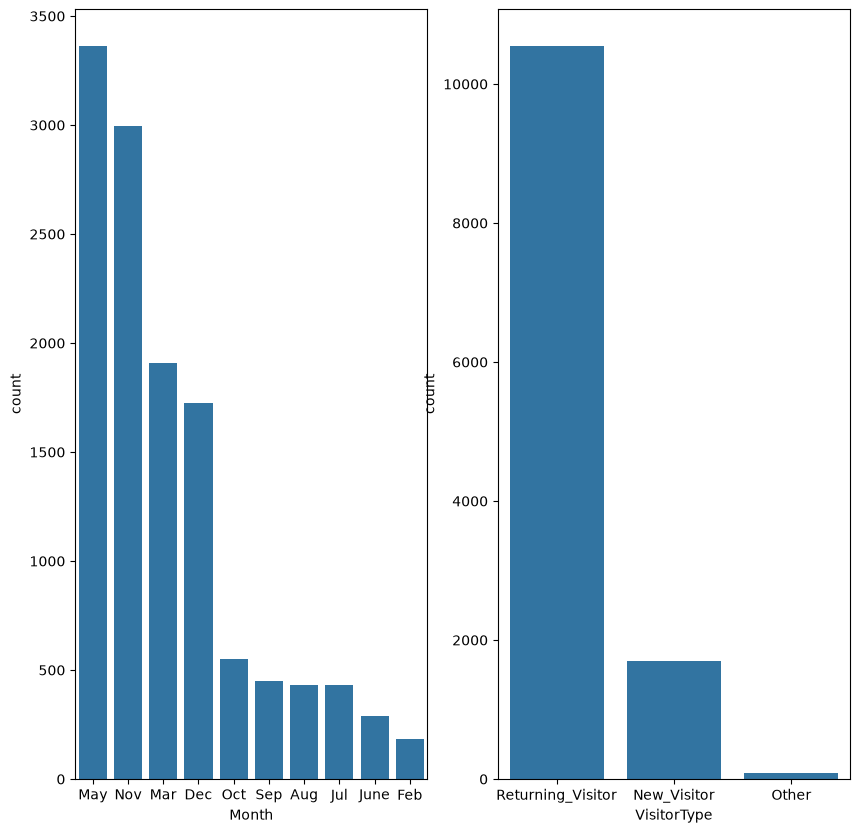

In [30]:
#For categorical data we can use distributions and look at the values

fig, axis= plt.subplots(1,2, figsize=(10,10))

sb.barplot(dataset['Month'].value_counts(), ax=axis[0])
sb.barplot(dataset['VisitorType'].value_counts(),ax=axis[1])

## BarPlots Study:

As we can see of all the months studied we can see a pattern: November and December in a pair because the Christmas shopping before the gifts period.

May and Mar we could say that they are often visited in this period because they are packed with holidays and people use their free time for internet shopping.


### After this we can do a correlation analysis:

We have to drop all the features that are not numerical, that is to say, the last 2 features that we use in the BarPlots



In [31]:
correlation = dataset.corr(numeric_only=True)
correlation.style.background_gradient(cmap='managua')

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,Weekend,Revenue
Administrative,1.000000,0.601583,0.376850,0.255848,0.431119,0.373939,-0.223563,-0.316483,0.098990,-0.094778,-0.006347,-0.025035,-0.005487,-0.033561,0.026417,0.138917
Administrative_Duration,0.601583,1.000000,0.302710,0.238031,0.289087,0.355422,-0.144170,-0.205798,0.067608,-0.073304,-0.007343,-0.015392,-0.005561,-0.014376,0.014990,0.093587
Informational,0.376850,0.302710,1.000000,0.618955,0.374164,0.387505,-0.116114,-0.163666,0.048632,-0.048219,-0.009527,-0.038235,-0.029169,-0.034491,0.035785,0.095200
Informational_Duration,0.255848,0.238031,0.618955,1.000000,0.280046,0.347364,-0.074067,-0.105276,0.030861,-0.030577,-0.009579,-0.019285,-0.027144,-0.024675,0.024078,0.070345
ProductRelated,0.431119,0.289087,0.374164,0.280046,1.000000,0.860927,-0.204578,-0.292526,0.056282,-0.023958,0.004290,-0.013146,-0.038122,-0.043064,0.016092,0.158538
ProductRelated_Duration,0.373939,0.355422,0.387505,0.347364,0.860927,1.000000,-0.184541,-0.251984,0.052823,-0.036380,0.002976,-0.007380,-0.033091,-0.036377,0.007311,0.152373
BounceRates,-0.223563,-0.144170,-0.116114,-0.074067,-0.204578,-0.184541,1.000000,0.913004,-0.119386,0.072702,0.023823,-0.015772,-0.006485,0.078286,-0.046514,-0.150673
ExitRates,-0.316483,-0.205798,-0.163666,-0.105276,-0.292526,-0.251984,0.913004,1.000000,-0.174498,0.102242,0.014567,-0.004442,-0.008907,0.078616,-0.062587,-0.207071
PageValues,0.098990,0.067608,0.048632,0.030861,0.056282,0.052823,-0.119386,-0.174498,1.000000,-0.063541,0.018508,0.045592,0.011315,0.012532,0.012002,0.492569
SpecialDay,-0.094778,-0.073304,-0.048219,-0.030577,-0.023958,-0.036380,0.072702,0.102242,-0.063541,1.000000,0.012652,0.003499,-0.016098,0.052301,-0.016767,-0.082305


## Correlation conclusions:

As we can see the upper left body is Pretty tightly connecetd because every feature until BounceRates is interwinded with each other. But there is an interesting breakthrough that makes a lot of sense. We can see that Revenue and PageValue are pretty much connected with a whoping 0.4925 , that is translated in: if the page is valueable (pretty, efficient, intuitive) that is gonna make more sales.

Administrative                Axes(0.125,0.786098;0.352273x0.0939024)
Administrative_Duration    Axes(0.547727,0.786098;0.352273x0.0939024)
Informational                 Axes(0.125,0.673415;0.352273x0.0939024)
Informational_Duration     Axes(0.547727,0.673415;0.352273x0.0939024)
ProductRelated                Axes(0.125,0.560732;0.352273x0.0939024)
ProductRelated_Duration    Axes(0.547727,0.560732;0.352273x0.0939024)
BounceRates                   Axes(0.125,0.448049;0.352273x0.0939024)
ExitRates                  Axes(0.547727,0.448049;0.352273x0.0939024)
PageValues                    Axes(0.125,0.335366;0.352273x0.0939024)
SpecialDay                 Axes(0.547727,0.335366;0.352273x0.0939024)
OperatingSystems              Axes(0.125,0.222683;0.352273x0.0939024)
Browser                    Axes(0.547727,0.222683;0.352273x0.0939024)
Region                            Axes(0.125,0.11;0.352273x0.0939024)
TrafficType                    Axes(0.547727,0.11;0.352273x0.0939024)
dtype: object

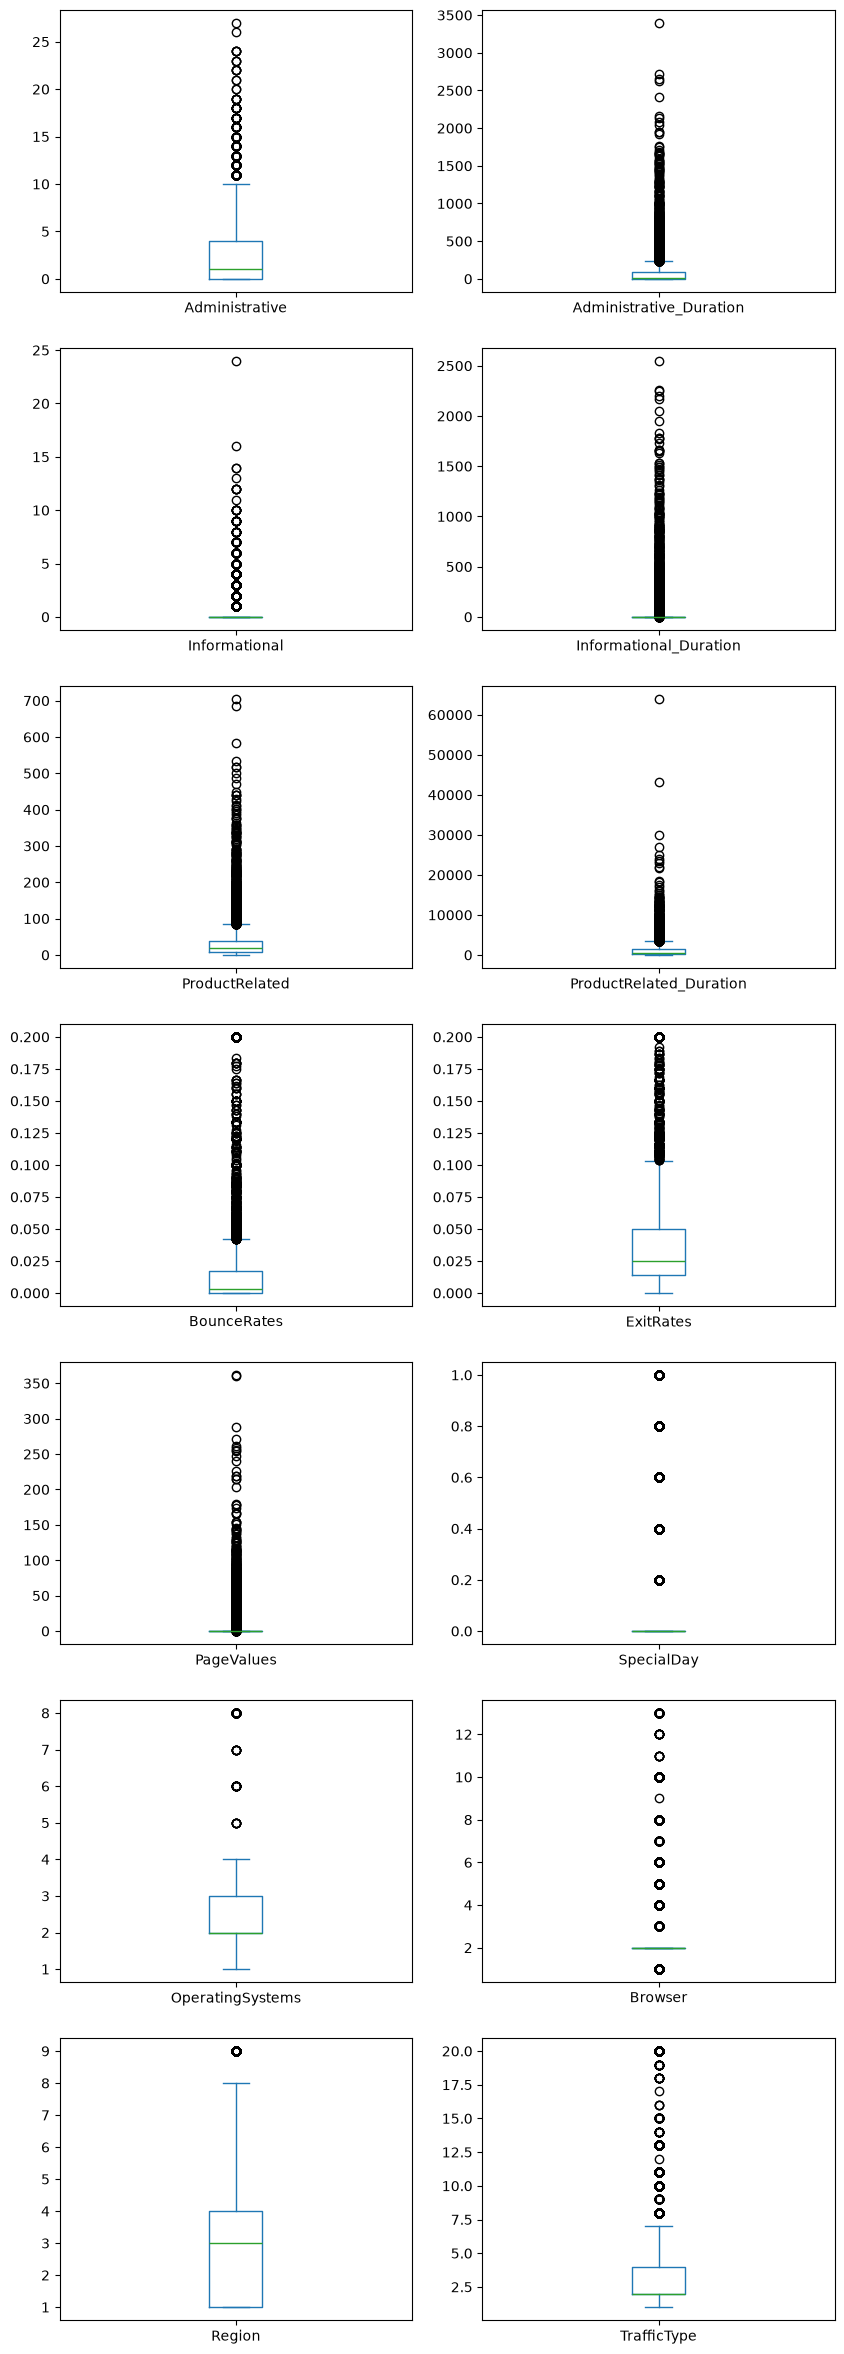

In [51]:
#Boxplots for the data to check atypical data:

cols=['Administrative','Administrative_Duration','Informational','Informational_Duration'
        ,'ProductRelated','ProductRelated_Duration','BounceRates','ExitRates'
            ,'PageValues','SpecialDay','OperatingSystems','Browser','Region','TrafficType']

dataset[cols].plot(kind='box',subplots=True,sharey=False,figsize=(10,30),layout=(7,2),sharex=False)